In [ ]:
!pip -q install pandas numpy matplotlib seaborn

In [ ]:
from getpass import getpass
import os

os.environ["GROQ_API_KEY"] = getpass(
    "Enter your Groq API Key: "
)

print("Groq API key configured successfully!")

Enter your Groq API Key: ··········
Groq API key configured successfully!


In [ ]:
!pip install -q groq

import os
from groq import Groq

client = Groq(
    api_key=os.environ["GROQ_API_KEY"]
)

MODEL = "openai/gpt-oss-20b"

print("Groq API connected!")

Groq API connected!


In [ ]:
response = client.chat.completions.create(
    model=MODEL,
    messages=[
        {
            "role": "user",
            "content": "Explain what a cyber threat is in simple words."
        }
    ],
    temperature=0.3
)

print(response.choices[0].message.content)

A **cyber threat** is any danger that can hurt computers, the internet, or the information stored on them.  
Think of it like a bad person or a harmful thing that tries to break into a computer system, steal data, or make the system stop working.  

Examples in plain terms:

| Threat | What it does | Why it matters |
|--------|--------------|----------------|
| **Virus / Malware** | A program that copies itself and damages files or steals info. | It can slow down or crash your computer. |
| **Hacking** | Someone uses clever tricks to get into a system they shouldn’t. | They can steal passwords, money, or sensitive data. |
| **Phishing** | Fake emails or websites that trick you into giving away passwords. | You might unknowingly give away your login details. |
| **Denial‑of‑Service (DoS)** | Overloading a website so it can’t be used. | Legitimate users can’t access the site. |

In short, a cyber threat is any potential attack or problem that can compromise the security, privacy, or avai

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import os
import re
import json
import ast
import logging
import ipaddress

from datasets import load_dataset
from itertools import islice
from groq import Groq

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
client = Groq(
    api_key=os.environ["GROQ_API_KEY"]
)

MODEL = "openai/gpt-oss-20b"

print("AI client initialized successfully!")

AI client initialized successfully!


In [ ]:
day_files = {
    "Monday": "https://huggingface.co/datasets/bvk/CICIDS-2017/resolve/main/monday.csv",
    "Tuesday": "https://huggingface.co/datasets/bvk/CICIDS-2017/resolve/main/tuesday.csv",
    "Wednesday": "https://huggingface.co/datasets/bvk/CICIDS-2017/resolve/main/wednesday.csv",
    "Thursday": "https://huggingface.co/datasets/bvk/CICIDS-2017/resolve/main/thursday.csv",
    "Friday": "https://huggingface.co/datasets/bvk/CICIDS-2017/resolve/main/friday.csv"
}

day_samples = []

for day, url in day_files.items():

    print(f"Loading {day}...")

    day_data = load_dataset(
        "csv",
        data_files=url,
        split="train",
        streaming=True
    )

    records = list(islice(iter(day_data), 10000))

    day_df = pd.DataFrame(records)
    day_df["Capture_Day"] = day

    day_samples.append(day_df)

df = pd.concat(day_samples, ignore_index=True)

print("\nDataset loaded successfully!")
print("Dataset shape:", df.shape)

Loading Monday...
Loading Tuesday...
Loading Wednesday...
Loading Thursday...
Loading Friday...

Dataset loaded successfully!
Dataset shape: (50000, 90)


In [ ]:
print("Dataset dimensions:", df.shape)

print("\nAvailable columns:")
print(df.columns.tolist())

print("\nFirst five records:")
display(df.head())

print("\nDataset information:")
df.info()

Dataset dimensions: (50000, 90)

Available columns:
['Src IP dec', 'Src Port', 'Dst IP dec', 'Dst Port', 'Protocol', 'Timestamp', 'Flow Duration', 'Total Fwd Packet', 'Total Bwd packets', 'Total Length of Fwd Packet', 'Total Length of Bwd Packet', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd RST Flags', 'Bwd RST Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Packet Length Min', 'Packet Length Max', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN F

,Src IP dec,Src Port,Dst IP dec,Dst Port,Protocol,Timestamp,Flow Duration,Total Fwd Packet,Total Bwd packets,Total Length of Fwd Packet,...,Idle Mean,Idle Std,Idle Max,Idle Min,ICMP Code,ICMP Type,Total TCP Flow Time,Label,Attempted Category,Capture_Day
0,134610945,0,134219268,0,0,56:34.2,119719148,231,0,0,...,12685486.0,5.296658e+06,20694308,6499982,-1,-1,0,BENIGN,-1,Monday
1,3232238089,123,3232238083,123,17,56:55.4,65511209,6,6,288,...,64004884.0,0.000000e+00,64004884,64004884,-1,-1,0,BENIGN,-1,Monday
2,3232238092,5353,3758096635,5353,17,57:21.1,113976922,267,0,20447,...,25498178.0,1.883305e+07,48523116,5463561,-1,-1,0,BENIGN,-1,Monday
3,3232238092,123,2550302004,123,17,57:31.6,67037196,8,8,384,...,55956316.0,0.000000e+00,55956316,55956316,-1,-1,0,BENIGN,-1,Monday
4,3232238092,123,760155097,123,17,57:30.6,68045057,8,8,384,...,56943904.0,0.000000e+00,56943904,56943904,-1,-1,0,BENIGN,-1,Monday



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 90 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Src IP dec                  50000 non-null  int64  
 1   Src Port                    50000 non-null  int64  
 2   Dst IP dec                  50000 non-null  int64  
 3   Dst Port                    50000 non-null  int64  
 4   Protocol                    50000 non-null  int64  
 5   Timestamp                   50000 non-null  object 
 6   Flow Duration               50000 non-null  int64  
 7   Total Fwd Packet            50000 non-null  int64  
 8   Total Bwd packets           50000 non-null  int64  
 9   Total Length of Fwd Packet  50000 non-null  int64  
 10  Total Length of Bwd Packet  50000 non-null  int64  
 11  Fwd Packet Length Max       50000 non-null  int64  
 12  Fwd Packet Length Min       50000 non-null  int64  
 13  Fwd Packe

In [ ]:
print("Different attack categories:")

display(df["Label"].value_counts())

Different attack categories:


,count
Label,
BENIGN,49766
DoS Slowloris,221
FTP-Patator,10
Web Attack - Brute Force - Attempted,2
FTP-Patator - Attempted,1


In [ ]:
missing_values = df.isnull().sum()

display(
    missing_values[missing_values > 0]
)

,0


In [ ]:
df.to_csv(
    "cyber_threat_log_inspector.csv",
    index=False
)

print("Initial cybersecurity dataset saved!")

Initial cybersecurity dataset saved!


In [ ]:
from datasets import load_dataset
from itertools import islice

# Preserve our initial dataset
df_initial = df.copy()

day_files = {
    "Monday": "https://huggingface.co/datasets/bvk/CICIDS-2017/resolve/main/monday.csv",
    "Tuesday": "https://huggingface.co/datasets/bvk/CICIDS-2017/resolve/main/tuesday.csv",
    "Wednesday": "https://huggingface.co/datasets/bvk/CICIDS-2017/resolve/main/wednesday.csv",
    "Thursday": "https://huggingface.co/datasets/bvk/CICIDS-2017/resolve/main/thursday.csv",
    "Friday": "https://huggingface.co/datasets/bvk/CICIDS-2017/resolve/main/friday.csv"
}

samples = []

for day, url in day_files.items():

    print("Sampling:", day)

    data = load_dataset(
        "csv",
        data_files=url,
        split="train",
        streaming=True
    )

    # Shuffle the streaming records
    shuffled_data = data.shuffle(
        seed=42,
        buffer_size=100000
    )

    records = list(
        islice(iter(shuffled_data), 10000)
    )

    day_df = pd.DataFrame(records)
    day_df["Capture_Day"] = day

    samples.append(day_df)

# Combine all daily samples
df = pd.concat(samples, ignore_index=True)

print("New dataset shape:", df.shape)

display(df["Label"].value_counts())

Sampling: Monday
Sampling: Tuesday
Sampling: Wednesday
Sampling: Thursday
Sampling: Friday
New dataset shape: (50000, 90)


,count
Label,
BENIGN,39768
DoS Hulk,6568
DDoS,1458
Infiltration - Portscan,815
DoS Slowloris,377
DoS Slowhttptest - Attempted,345
Botnet - Attempted,241
DoS Slowhttptest,186
DoS Slowloris - Attempted,175


In [ ]:
print("Missing values:", df.isnull().sum().sum())

print("Duplicate records:", df.duplicated().sum())

print("\nAttack distribution:")
display(df["Label"].value_counts())

print("\nDaily distribution:")
display(df["Capture_Day"].value_counts())

Missing values: 0
Duplicate records: 0

Attack distribution:


,count
Label,
BENIGN,39768
DoS Hulk,6568
DDoS,1458
Infiltration - Portscan,815
DoS Slowloris,377
DoS Slowhttptest - Attempted,345
Botnet - Attempted,241
DoS Slowhttptest,186
DoS Slowloris - Attempted,175



Daily distribution:


,count
Capture_Day,
Monday,10000
Tuesday,10000
Wednesday,10000
Thursday,10000
Friday,10000


In [ ]:
import ipaddress

def convert_ip(value):
    try:
        return str(ipaddress.IPv4Address(int(value)))
    except (ValueError, TypeError, OverflowError):
        return value

df["Source_IP"] = df["Src IP dec"].apply(convert_ip)

df["Destination_IP"] = df["Dst IP dec"].apply(convert_ip)

protocol_mapping = {
    1: "ICMP",
    6: "TCP",
    17: "UDP"
}

df["Protocol_Name"] = (
    df["Protocol"].map(protocol_mapping).fillna("Other")
)

df["Traffic_Status"] = np.where(
    df["Label"].str.upper() == "BENIGN",
    "Normal",
    "Malicious"
)

print("Cybersecurity features created!")

display(
    df[[
        "Source_IP",
        "Destination_IP",
        "Src Port",
        "Dst Port",
        "Protocol_Name",
        "Label",
        "Traffic_Status"
    ]].head()
)

Cybersecurity features created!


,Source_IP,Destination_IP,Src Port,Dst Port,Protocol_Name,Label,Traffic_Status
0,192.168.10.5,104.16.14.15,51800,443,TCP,BENIGN,Normal
1,192.168.10.14,192.168.10.3,62670,53,UDP,BENIGN,Normal
2,192.168.10.3,192.168.10.1,62343,53,UDP,BENIGN,Normal
3,192.168.10.3,192.168.10.1,60759,53,UDP,BENIGN,Normal
4,192.168.10.3,192.168.10.1,60091,53,UDP,BENIGN,Normal


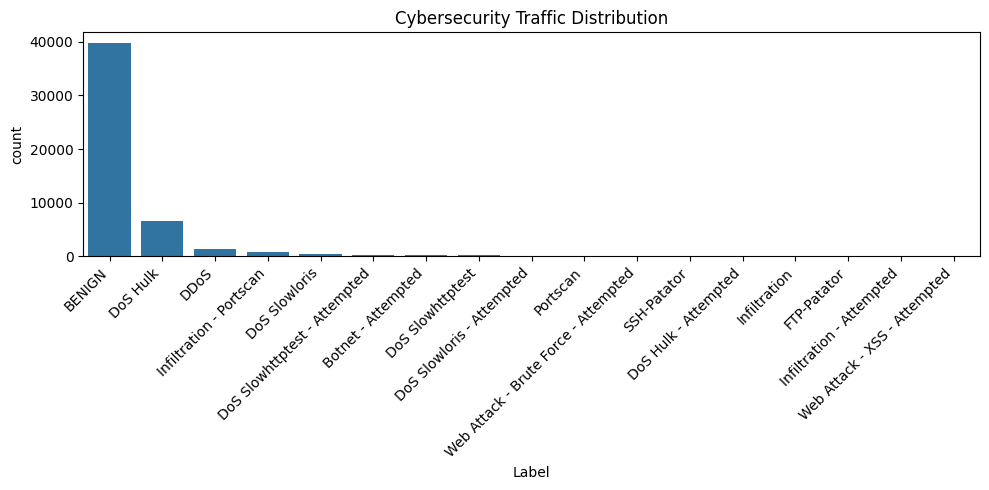

In [ ]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="Label",
    order=df["Label"].value_counts().index
)

plt.title("Cybersecurity Traffic Distribution")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

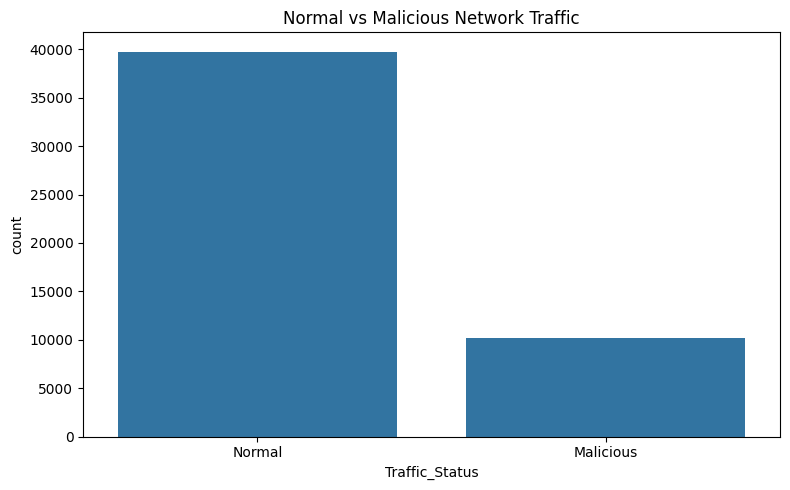

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Traffic_Status"
)

plt.title("Normal vs Malicious Network Traffic")
plt.tight_layout()
plt.show()

In [ ]:
# Make sure important columns are available

if "Source_IP" not in df.columns:
    df["Source_IP"] = df["Src IP dec"].apply(convert_ip)

if "Destination_IP" not in df.columns:
    df["Destination_IP"] = df["Dst IP dec"].apply(convert_ip)

if "Traffic_Status" not in df.columns:
    df["Traffic_Status"] = np.where(
        df["Label"].str.upper() == "BENIGN",
        "Normal",
        "Malicious"
    )

print("Dataset is ready for analysis!")
print("Total records:", len(df))

Dataset is ready for analysis!
Total records: 50000


In [ ]:
def get_dataset_overview():

    return {
        "total_records": len(df),
        "total_columns": len(df.columns),
        "attack_categories": df["Label"].nunique(),
        "normal_records": int(
            (df["Traffic_Status"] == "Normal").sum()
        ),
        "malicious_records": int(
            (df["Traffic_Status"] == "Malicious").sum()
        ),
        "capture_days": df["Capture_Day"].nunique()
    }


def get_attack_distribution():

    return df["Label"].value_counts().to_dict()


def get_suspicious_ips():

    malicious = df[
        df["Traffic_Status"] == "Malicious"
    ]

    return (
        malicious["Source_IP"]
        .value_counts()
        .head(10)
        .to_dict()
    )


def get_targeted_ports():

    malicious = df[
        df["Traffic_Status"] == "Malicious"
    ]

    return (
        malicious["Dst Port"]
        .value_counts()
        .head(10)
        .to_dict()
    )


def get_protocol_distribution():

    return df["Protocol_Name"].value_counts().to_dict()


def get_daily_traffic():

    return (
        df.groupby("Capture_Day")["Label"]
        .count()
        .to_dict()
    )


print("All analysis functions created successfully!")

All analysis functions created successfully!


In [ ]:
print("DATASET OVERVIEW")
print(get_dataset_overview())

print("\nATTACK DISTRIBUTION")
print(get_attack_distribution())

print("\nTOP SUSPICIOUS SOURCE IPS")
print(get_suspicious_ips())

print("\nMOST TARGETED PORTS")
print(get_targeted_ports())

print("\nPROTOCOL DISTRIBUTION")
print(get_protocol_distribution())

print("\nDAILY TRAFFIC")
print(get_daily_traffic())

DATASET OVERVIEW
{'total_records': 50000, 'total_columns': 94, 'attack_categories': 17, 'normal_records': 39768, 'malicious_records': 10232, 'capture_days': 5}

ATTACK DISTRIBUTION
{'BENIGN': 39768, 'DoS Hulk': 6568, 'DDoS': 1458, 'Infiltration - Portscan': 815, 'DoS Slowloris': 377, 'DoS Slowhttptest - Attempted': 345, 'Botnet - Attempted': 241, 'DoS Slowhttptest': 186, 'DoS Slowloris - Attempted': 175, 'Portscan': 49, 'Web Attack - Brute Force - Attempted': 9, 'SSH-Patator': 2, 'DoS Hulk - Attempted': 2, 'Infiltration': 2, 'FTP-Patator': 1, 'Infiltration - Attempted': 1, 'Web Attack - XSS - Attempted': 1}

TOP SUSPICIOUS SOURCE IPS
{'172.16.0.1': 9175, '192.168.10.8': 886, '192.168.10.15': 65, '192.168.10.14': 37, '192.168.10.5': 36, '192.168.10.9': 32, '192.168.10.25': 1}

MOST TARGETED PORTS
{80: 9138, 8080: 242, 0: 6, 1198: 5, 444: 5, 497: 4, 6101: 4, 19315: 4, 1: 4, 125: 4}

PROTOCOL DISTRIBUTION
{'UDP': 34554, 'TCP': 15310, 'Other': 105, 'ICMP': 31}

DAILY TRAFFIC
{'Friday': 100

In [ ]:
def understand_question(question):

    prompt = f"""
    You are an intent classifier for a cybersecurity
    dataset understanding assistant.

    Classify the user's question into exactly ONE category:

    OVERVIEW
    ATTACKS
    SUSPICIOUS_IPS
    TARGETED_PORTS
    PROTOCOLS
    DAILY_TRAFFIC
    HELP

    User question: {question}

    Return only the category name.
    """

    response = client.chat.completions.create(
        model=MODEL,
        messages=[
            {
                "role": "user",
                "content": prompt
            }
        ],
        temperature=0
    )

    intent = response.choices[0].message.content.strip()

    allowed_intents = {
        "OVERVIEW",
        "ATTACKS",
        "SUSPICIOUS_IPS",
        "TARGETED_PORTS",
        "PROTOCOLS",
        "DAILY_TRAFFIC",
        "HELP"
    }

    if intent not in allowed_intents:
        return "HELP"

    return intent


print("Question understanding function created!")

Question understanding function created!


In [ ]:
analysis_functions = {
    "OVERVIEW": get_dataset_overview,
    "ATTACKS": get_attack_distribution,
    "SUSPICIOUS_IPS": get_suspicious_ips,
    "TARGETED_PORTS": get_targeted_ports,
    "PROTOCOLS": get_protocol_distribution,
    "DAILY_TRAFFIC": get_daily_traffic
}


def analyze_question(question):

    intent = understand_question(question)

    if intent == "HELP":
        return {
            "intent": intent,
            "data": None
        }

    result = analysis_functions[intent]()

    return {
        "intent": intent,
        "data": result
    }


print("Question-to-analysis mapping completed!")

Question-to-analysis mapping completed!


In [ ]:
def generate_answer(question):

    analysis = analyze_question(question)

    if analysis["intent"] == "HELP":
        return """
        I can help you explore:
        1. Dataset overview
        2. Attack distribution
        3. Suspicious source IPs
        4. Targeted destination ports
        5. Network protocols
        6. Daily traffic distribution

        Try asking one of these questions!
        """

    prompt = f"""
    You are a cybersecurity dataset analysis assistant.

    Answer the user's question using ONLY the data below.

    User question:
    {question}

    Actual dataset analysis:
    {json.dumps(analysis["data"], indent=2)}

    Instructions:
    - Explain the results in simple language.
    - Include relevant numbers.
    - Never invent statistics.
    - Mention that results represent our loaded sample
      of the CIC-IDS2017 dataset.
    - Do not claim that an IP is a confirmed attacker.
    - If the data is insufficient, say so clearly.
    """

    response = client.chat.completions.create(
        model=MODEL,
        messages=[
            {
                "role": "user",
                "content": prompt
            }
        ],
        temperature=0.2
    )

    return response.choices[0].message.content


print("AI answer generation function created!")

AI answer generation function created!


User Interface

In [ ]:
!pip install -q -U gradio

In [ ]:
import gradio as gr
import matplotlib.pyplot as plt
import pandas as pd

print("Gradio imported successfully!")

Gradio imported successfully!


In [ ]:
overview = get_dataset_overview()

total_records = overview["total_records"]
total_attacks = overview["malicious_records"]
normal_records = overview["normal_records"]
attack_types = overview["attack_categories"]

print("Dashboard statistics prepared!")

Dashboard statistics prepared!


In [ ]:
custom_css = """
.gradio-container {
    background: #111111 !important;
    color: #ffffff !important;
    font-family: 'Inter', sans-serif;
}

.main-title {
    color: #F97316 !important;
    font-size: 32px !important;
    font-weight: 800 !important;
}

.subtitle {
    color: #bbbbbb !important;
    font-size: 14px !important;
}

.stat-card {
    background: #232323;
    border: 1px solid #393939;
    border-left: 4px solid #F97316;
    border-radius: 12px;
    padding: 18px;
}

.stat-number {
    color: #FFB347;
    font-size: 28px;
    font-weight: bold;
}

.stat-label {
    color: #bbbbbb;
    font-size: 13px;
}

.section-title {
    color: #F97316;
    font-weight: 700;
}

button.primary {
    background: #F97316 !important;
    color: #111111 !important;
    border: none !important;
}

footer {
    display: none !important;
}
"""

In [ ]:
def create_attack_chart():

    counts = df["Label"].value_counts()

    fig, ax = plt.subplots(figsize=(9, 4))

    fig.patch.set_facecolor("#181818")
    ax.set_facecolor("#181818")

    counts.plot(
        kind="bar",
        ax=ax,
        color="#F97316"
    )

    ax.set_title(
        "Cybersecurity Attack Distribution",
        color="white"
    )

    ax.set_xlabel("Attack Type", color="white")
    ax.set_ylabel("Number of Records", color="white")

    ax.tick_params(colors="white")
    ax.spines["bottom"].set_color("#777777")
    ax.spines["left"].set_color("#777777")

    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()

    return fig


In [ ]:
def respond(message, history):

    if not message.strip():
        return "", history

    try:
        answer = generate_answer(message)

    except Exception as e:
        answer = f"Sorry, something went wrong: {str(e)}"

    history = history or []

    history = history + [
        {"role": "user", "content": message},
        {"role": "assistant", "content": answer}
    ]

    return "", history


def ask_suggestion(question, history):

    try:
        answer = generate_answer(question)

    except Exception as e:
        answer = f"Error: {str(e)}"

    history = history or []

    history = history + [
        {"role": "user", "content": question},
        {"role": "assistant", "content": answer}
    ]

    return history

In [ ]:
with gr.Blocks(
    title="CyberScope AI"
) as demo:

    # Header
    gr.Markdown(
        """
        # 🛡️ CyberScope AI
        ### Intelligent Cybersecurity Dataset Understanding Assistant

        Explore network traffic. Understand threats. Ask questions.
        """,
        elem_classes=["main-title"]
    )

    gr.Markdown(
        "POWERED BY CIC-IDS2017 • GROQ AI • PYTHON",
        elem_classes=["subtitle"]
    )

    gr.Markdown("## 📊 Dataset Overview")

    # Statistics
    with gr.Row():

        gr.HTML(f"""
        <div class="stat-card">
            <div class="stat-label">TOTAL RECORDS</div>
            <div class="stat-number">{total_records:,}</div>
        </div>
        """)

        gr.HTML(f"""
        <div class="stat-card">
            <div class="stat-label">MALICIOUS FLOWS</div>
            <div class="stat-number">{total_attacks:,}</div>
        </div>
        """)

        gr.HTML(f"""
        <div class="stat-card">
            <div class="stat-label">NORMAL FLOWS</div>
            <div class="stat-number">{normal_records:,}</div>
        </div>
        """)

        gr.HTML(f"""
        <div class="stat-card">
            <div class="stat-label">ATTACK LABELS</div>
            <div class="stat-number">{attack_types}</div>
        </div>
        """)

    gr.Markdown("---")

    # Dashboard chart
    gr.Markdown(
        "## 📈 Network Traffic Analysis",
        elem_classes=["section-title"]
    )

    gr.Plot(
        value=create_attack_chart(),
        label="Attack Distribution"
    )

    gr.Markdown("---")

    # AI Chat section
    gr.Markdown(
        "## 🤖 Ask CyberScope AI",
        elem_classes=["section-title"]
    )

    gr.Markdown(
        "Ask questions about your cybersecurity dataset "
        "using natural language."
    )

    chatbot = gr.Chatbot(
        height=400,
        label="AI Assistant"
    )

    # Suggested prompts
    gr.Markdown("### 💡 Suggested Questions")

    with gr.Row():
        prompt1 = gr.Button("Dataset Overview")
        prompt2 = gr.Button("Attack Distribution")
        prompt3 = gr.Button("Suspicious IPs")

    with gr.Row():
        prompt4 = gr.Button("Targeted Ports")
        prompt5 = gr.Button("Protocol Analysis")
        prompt6 = gr.Button("Daily Traffic")

    # Custom question
    gr.Markdown("### ✍️ Ask Your Own Question")

    with gr.Row():
        msg = gr.Textbox(
            placeholder="Example: Which IP addresses have the most malicious traffic?",
            show_label=False,
            scale=8
        )

        send = gr.Button(
            "Analyze →",
            variant="primary",
            scale=1
        )

    # Chat interactions
    msg.submit(
        respond,
        inputs=[msg, chatbot],
        outputs=[msg, chatbot]
    )

    send.click(
        respond,
        inputs=[msg, chatbot],
        outputs=[msg, chatbot]
    )

    # Suggested prompt actions
    prompt1.click(
        lambda h: ask_suggestion(
            "Give me an overview of this dataset", h
        ),
        inputs=chatbot,
        outputs=chatbot
    )

    prompt2.click(
        lambda h: ask_suggestion(
            "What are the different types of cyberattacks?", h
        ),
        inputs=chatbot,
        outputs=chatbot
    )

    prompt3.click(
        lambda h: ask_suggestion(
            "Which source IPs have the most malicious traffic?", h
        ),
        inputs=chatbot,
        outputs=chatbot
    )

    prompt4.click(
        lambda h: ask_suggestion(
            "Which destination ports are targeted the most?", h
        ),
        inputs=chatbot,
        outputs=chatbot
    )

    prompt5.click(
        lambda h: ask_suggestion(
            "Show me the network protocol distribution", h
        ),
        inputs=chatbot,
        outputs=chatbot
    )

    prompt6.click(
        lambda h: ask_suggestion(
            "How is traffic distributed across the five days?", h
        ),
        inputs=chatbot,
        outputs=chatbot
    )

    gr.Markdown(
        """
        ---
        <center>
        <small>CyberScope AI | Academic Project | CIC-IDS2017</small>
        </center>
        """
    )

# Launch with modern parameter configuration
demo.launch(
    theme=gr.themes.Base(
        primary_hue="orange",
        neutral_hue="slate"
    ),
    css=custom_css,
    share=True
)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://9f03ddda33e59a279b.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
demo.launch(
    share=True,
    debug=True
)

Rerunning server... use `close()` to stop if you need to change `launch()` parameters.
----
Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://9f03ddda33e59a279b.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://9f03ddda33e59a279b.gradio.live


In [ ]:
def explore_dataset(day, attack, limit):

    filtered_df = df.copy()

    # Filter by capture day
    if day != "All Days":
        filtered_df = filtered_df[
            filtered_df["Capture_Day"] == day
        ]

    # Filter by attack category
    if attack != "All Attacks":
        filtered_df = filtered_df[
            filtered_df["Label"] == attack
        ]

    total = len(filtered_df)

    preview = filtered_df.head(int(limit))

    summary = f"""
    ### Dataset Exploration Results

    - Matching records: {total:,}
    - Displayed records: {len(preview):,}
    - Selected day: {day}
    - Selected attack: {attack}
    """

    return preview, summary

In [ ]:
def create_filtered_chart(day, attack):

    filtered_df = df.copy()

    if day != "All Days":
        filtered_df = filtered_df[
            filtered_df["Capture_Day"] == day
        ]

    if attack != "All Attacks":
        filtered_df = filtered_df[
            filtered_df["Label"] == attack
        ]

    counts = filtered_df["Label"].value_counts()

    fig, ax = plt.subplots(figsize=(9, 4))

    fig.patch.set_facecolor("#181818")
    ax.set_facecolor("#181818")

    counts.plot(
        kind="bar",
        color="#F97316",
        ax=ax
    )

    ax.set_title(
        "Filtered Attack Distribution",
        color="white"
    )

    ax.tick_params(colors="white")
    ax.set_xlabel("Attack Category", color="white")
    ax.set_ylabel("Records", color="white")

    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()

    return fig

In [ ]:
import tempfile

def export_filtered_data(day, attack):

    filtered_df = df.copy()

    if day != "All Days":
        filtered_df = filtered_df[
            filtered_df["Capture_Day"] == day
        ]

    if attack != "All Attacks":
        filtered_df = filtered_df[
            filtered_df["Label"] == attack
        ]

    if filtered_df.empty:
        return None

    file_path = tempfile.NamedTemporaryFile(
        suffix=".csv",
        delete=False
    ).name

    filtered_df.to_csv(file_path, index=False)

    return file_path

In [ ]:
with gr.Blocks(
    theme=gr.themes.Base(
        primary_hue="orange",
        neutral_hue="slate"
    ),
    css=custom_css,
    title="CyberScope AI - Dataset Explorer"
) as explorer_demo:

    gr.Markdown(
        """
        # 🛡️ CyberScope AI
        ## Dataset Explorer

        Explore, filter and understand cybersecurity network traffic.
        """
    )

    with gr.Row():

        day_filter = gr.Dropdown(
            choices=[
                "All Days",
                "Monday",
                "Tuesday",
                "Wednesday",
                "Thursday",
                "Friday"
            ],
            value="All Days",
            label="Select Capture Day"
        )

        attack_filter = gr.Dropdown(
            choices=["All Attacks"] +
                    sorted(df["Label"].unique().tolist()),
            value="All Attacks",
            label="Select Attack Category"
        )

        row_limit = gr.Slider(
            minimum=10,
            maximum=500,
            value=100,
            step=10,
            label="Records to Display"
        )

    explore_button = gr.Button(
        "Explore Dataset",
        variant="primary"
    )

    result_summary = gr.Markdown()

    data_table = gr.Dataframe(
        label="Filtered Network Records",
        interactive=False
    )

    chart_output = gr.Plot(
        label="Attack Distribution"
    )

    gr.Markdown("### Download Your Filtered Dataset")

    download_button = gr.Button(
        "Prepare CSV Download",
        variant="primary"
    )

    download_file = gr.File(
        label="Your CSV File"
    )

    explore_button.click(
        explore_dataset,
        inputs=[
            day_filter,
            attack_filter,
            row_limit
        ],
        outputs=[
            data_table,
            result_summary
        ]
    ).then(
        create_filtered_chart,
        inputs=[
            day_filter,
            attack_filter
        ],
        outputs=chart_output
    )

    download_button.click(
        export_filtered_data,
        inputs=[
            day_filter,
            attack_filter
        ],
        outputs=download_file
    )

/tmp/ipykernel_906/822924902.py:1: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(


In [ ]:
explorer_demo.launch(
    share=True,
    debug=True
)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://3b21fcbc46d50dde4b.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/gradio/queueing.py", line 870, in process_events
    response = await route_utils.call_process_api(
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    ...<6 lines>...
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/gradio/route_utils.py", line 418, in call_process_api
    output = await app.get_blocks().process_api(
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    ...<12 lines>...
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/gradio/blocks.py", line 2698, in process_api
    result = await self.call_function(
             ^^^^^^^^^^^^^^^^^^^^^^^^^
    ...<9 lines>...
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/gradio/blocks.py", line 1963, in call_function
    prediction = await anyio.to_thread.run_sync(  # type: ignore
                 ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
        fn, *processed_input, limiter=self.limiter
        ^^^^^^^^^^^^^^

Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://3b21fcbc46d50dde4b.gradio.live


In [48]:
import gradio as gr
import pandas as pd
import matplotlib.pyplot as plt
import tempfile
import os

# -----------------------------------------
# 1. CHECK THE DATASET
# -----------------------------------------

if "df" not in globals():
    raise ValueError("Dataset not found. Run your dataset loading cells first.")

if "Label" not in df.columns:
    raise ValueError("The dataset must contain a 'Label' column.")

if "Capture_Day" not in df.columns:
    df["Capture_Day"] = "Unknown"

days = ["All Days"] + sorted(df["Capture_Day"].dropna().astype(str).unique().tolist())
attacks = ["All Attacks"] + sorted(df["Label"].dropna().astype(str).unique().tolist())

# Columns that will be shown in the explorer preview.
preferred_columns = [
    "Timestamp", "Source_IP", "Destination_IP",
    "Src Port", "Dst Port", "Protocol_Name",
    "Label", "Capture_Day"
]

preview_columns = [col for col in preferred_columns if col in df.columns]

# -----------------------------------------
# 2. OVERVIEW FUNCTIONS
# -----------------------------------------

def get_overview_text():
    total = len(df)
    normal = int((df["Label"].astype(str).str.upper() == "BENIGN").sum())
    malicious = total - normal
    attack_types = df["Label"].nunique()
    capture_days = df["Capture_Day"].nunique()

    return f"""
## Dataset Overview

| Metric | Value |
|---|---:|
| Total network flows | {total:,} |
| Normal network flows | {normal:,} |
| Non-benign labelled flows | {malicious:,} |
| Unique labels | {attack_types:,} |
| Capture days | {capture_days:,} |

**Dataset:** CIC-IDS2017
**Note:** These figures describe the dataset currently loaded in this Colab session.
"""

def create_overview_chart():
    counts = df["Label"].value_counts()

    fig, ax = plt.subplots(figsize=(10, 4))
    fig.patch.set_facecolor("#181818")
    ax.set_facecolor("#181818")

    counts.plot(kind="bar", color="#F97316", ax=ax)

    ax.set_title("Network Traffic Label Distribution", color="white")
    ax.set_xlabel("Traffic Label", color="white")
    ax.set_ylabel("Number of Flows", color="white")
    ax.tick_params(axis="x", colors="white", rotation=35)
    ax.tick_params(axis="y", colors="white")

    for spine in ax.spines.values():
        spine.set_color("#777777")

    plt.tight_layout()
    return fig

# -----------------------------------------
# 3. DATASET EXPLORER FUNCTIONS
# -----------------------------------------

def get_filtered_data(day, attack, limit):
    filtered = df.copy()

    if day != "All Days":
        filtered = filtered[filtered["Capture_Day"].astype(str) == day]

    if attack != "All Attacks":
        filtered = filtered[filtered["Label"].astype(str) == attack]

    total = len(filtered)
    preview = filtered[preview_columns].head(int(limit))

    summary = f"""
### Exploration Results

- **Matching records:** {total:,}
- **Records displayed:** {len(preview):,}
- **Selected day:** {day}
- **Selected attack:** {attack}
"""

    return preview, summary

def create_filtered_chart(day, attack):
    filtered = df.copy()

    if day != "All Days":
        filtered = filtered[filtered["Capture_Day"].astype(str) == day]

    if attack != "All Attacks":
        filtered = filtered[filtered["Label"].astype(str) == attack]

    counts = filtered["Label"].value_counts()

    fig, ax = plt.subplots(figsize=(9, 4))
    fig.patch.set_facecolor("#181818")
    ax.set_facecolor("#181818")

    if counts.empty:
        ax.text(0.5, 0.5, "No matching records found for this selection",
                color="white", ha="center", va="center", fontsize=12)
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.axis('off')
    else:
        counts.plot(kind="bar", color="#F97316", ax=ax)
        ax.set_title("Filtered Traffic Distribution", color="white")
        ax.set_xlabel("Traffic Label", color="white")
        ax.set_ylabel("Number of Flows", color="white")
        ax.tick_params(colors="white", rotation=35)

    plt.tight_layout()
    return fig

def export_filtered_data(day, attack):
    filtered = df.copy()

    if day != "All Days":
        filtered = filtered[filtered["Capture_Day"].astype(str) == day]

    if attack != "All Attacks":
        filtered = filtered[filtered["Label"].astype(str) == attack]

    if filtered.empty:
        return None

    file_path = tempfile.NamedTemporaryFile(
        suffix=".csv", delete=False
    ).name

    filtered.to_csv(file_path, index=False)
    return file_path

# -----------------------------------------
# 4. AI ASSISTANT FUNCTIONS
# -----------------------------------------

def chat_response(message, history):
    history = history or []

    if not message or not message.strip():
        return history, ""

    try:
        answer = generate_answer(message)
    except Exception as error:
        answer = f"Something went wrong: {str(error)}"

    updated_history = history + [
        {"role": "user", "content": message},
        {"role": "assistant", "content": answer}
    ]

    return updated_history, ""

def suggested_response(question, history):
    history = history or []

    try:
        answer = generate_answer(question)
    except Exception as error:
        answer = f"Something went wrong: {str(error)}"

    updated_history = history + [
        {"role": "user", "content": question},
        {"role": "assistant", "content": answer}
    ]

    return updated_history

# -----------------------------------------
# 5. ORANGE AND BLACK THEME
# -----------------------------------------

dashboard_css = """
.gradio-container {
    background: #111111 !important;
    color: #ffffff !important;
    font-family: Inter, sans-serif;
}
.main-heading {
    color: #F97316 !important;
    font-size: 34px !important;
    font-weight: 800 !important;
}
.sub-heading {
    color: #bbbbbb !important;
}
button.primary {
    background: #F97316 !important;
    color: #111111 !important;
    border: none !important;
}
"""

# -----------------------------------------
# 6. BUILD THE UNIFIED DASHBOARD
# -----------------------------------------

with gr.Blocks(
    title="CyberScope AI"
) as cyberscope_app:

    gr.Markdown("# 🛡️ CyberScope AI", elem_classes="main-heading")
    gr.Markdown(
        "Your AI-powered cybersecurity dataset understanding platform.",
        elem_classes="sub-heading"
    )

    with gr.Tabs():

        # OVERVIEW TAB
        with gr.Tab("📊 Overview"):
            gr.Markdown("## Dataset Summary")
            overview_output = gr.Markdown(
                value=get_overview_text()
            )
            overview_plot = gr.Plot(
                value=create_overview_chart()
            )

            refresh_overview = gr.Button(
                "Refresh Overview",
                variant="primary"
            )
            refresh_overview.click(
                fn=lambda: (
                    get_overview_text(),
                    create_overview_chart()
                ),
                outputs=[overview_output, overview_plot]
            )

        # DATASET EXPLORER TAB
        with gr.Tab("🔎 Dataset Explorer"):
            gr.Markdown("## Explore Network Traffic")

            with gr.Row():
                day_filter = gr.Dropdown(
                    choices=days,
                    value="All Days",
                    label="Capture Day"
                )

                attack_filter = gr.Dropdown(
                    choices=attacks,
                    value="All Attacks",
                    label="Traffic Label"
                )

                row_limit = gr.Slider(
                    minimum=10,
                    maximum=500,
                    value=100,
                    step=10,
                    label="Preview Rows"
                )

            explore_button = gr.Button(
                "Explore Dataset",
                variant="primary"
            )

            explorer_summary = gr.Markdown()

            explorer_table = gr.Dataframe(
                label="Network Traffic Records",
                interactive=False
            )

            explorer_plot = gr.Plot()

            explore_button.click(
                fn=get_filtered_data,
                inputs=[day_filter, attack_filter, row_limit],
                outputs=[explorer_table, explorer_summary]
            )

            explore_button.click(
                fn=create_filtered_chart,
                inputs=[day_filter, attack_filter],
                outputs=explorer_plot
            )

            gr.Markdown("### Export Filtered Dataset")

            export_button = gr.Button("Export CSV")
            export_file = gr.File(label="Your CSV File")

            export_button.click(
                fn=export_filtered_data,
                inputs=[day_filter, attack_filter],
                outputs=export_file
            )

        # AI ASSISTANT TAB
        with gr.Tab("🤖 AI Assistant"):
            gr.Markdown("## Ask CyberScope AI")
            gr.Markdown(
                "Ask questions about the CIC-IDS2017 network traffic dataset."
            )

            chatbot = gr.Chatbot(
                height=420,
                label="CyberScope AI Chat"
            )

            gr.Markdown("### Suggested Questions")

            with gr.Row():
                overview_btn = gr.Button("Dataset Overview")
                attack_btn = gr.Button("Attack Distribution")
                ip_btn = gr.Button("Suspicious Source IPs")

            with gr.Row():
                port_btn = gr.Button("Targeted Ports")
                protocol_btn = gr.Button("Network Protocols")
                daily_btn = gr.Button("Daily Traffic")

            overview_btn.click(
                fn=lambda history: suggested_response(
                    "Give me an overview of this dataset.", history
                ),
                inputs=chatbot,
                outputs=chatbot
            )

            attack_btn.click(
                fn=lambda history: suggested_response(
                    "Show me the attack distribution.", history
                ),
                inputs=chatbot,
                outputs=chatbot
            )

            ip_btn.click(
                fn=lambda history: suggested_response(
                    "Which source IPs appear most frequently in non-benign labelled traffic?",
                    history
                ),
                inputs=chatbot,
                outputs=chatbot
            )

            port_btn.click(
                fn=lambda history: suggested_response(
                    "Which destination ports appear most frequently in non-benign labelled traffic?",
                    history
                ),
                inputs=chatbot,
                outputs=chatbot
            )

            protocol_btn.click(
                fn=lambda history: suggested_response(
                    "Explain the network protocol distribution.", history
                ),
                inputs=chatbot,
                outputs=chatbot
            )

            daily_btn.click(
                fn=lambda history: suggested_response(
                    "Show me the traffic distribution across capture days.",
                    history
                ),
                inputs=chatbot,
                outputs=chatbot
            )

            with gr.Row():
                message_box = gr.Textbox(
                    placeholder="Ask something about your dataset...",
                    label="Your Question",
                    scale=8
                )
                send_button = gr.Button("Send", variant="primary", scale=1)

            send_button.click(
                fn=chat_response,
                inputs=[message_box, chatbot],
                outputs=[chatbot, message_box]
            )

            message_box.submit(
                fn=chat_response,
                inputs=[message_box, chatbot],
                outputs=[chatbot, message_box]
            )

# -----------------------------------------
# 7. LAUNCH THE APPLICATION
# -----------------------------------------

cyberscope_app.launch(
    theme=gr.themes.Base(
        primary_hue="orange",
        neutral_hue="slate"
    ),
    css=dashboard_css,
    share=True,
    debug=True
)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://51b7e9bf639e7aaa1e.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://51b7e9bf639e7aaa1e.gradio.live


CYBERSCOPE AI - DATASET QUALITY AUDIT

Total records: 50,000
Total columns: 94
Duplicate records: 0
Infinite numerical values: 0
Missing-value columns: 0
Constant columns: 3

NORMAL VS NON-BENIGN-LABELLED TRAFFIC
Benign records: 39,768
Other labelled records: 10,232

MISSING VALUE REPORT
No missing values found.

CONSTANT COLUMNS
['Fwd URG Flags', 'Bwd URG Flags', 'URG Flag Count']

LABEL DISTRIBUTION


,Record Count,Percentage (%)
Label,,
BENIGN,39768,79.54
DoS Hulk,6568,13.14
DDoS,1458,2.92
Infiltration - Portscan,815,1.63
DoS Slowloris,377,0.75
DoS Slowhttptest - Attempted,345,0.69
Botnet - Attempted,241,0.48
DoS Slowhttptest,186,0.37
DoS Slowloris - Attempted,175,0.35



CAPTURE DAY DISTRIBUTION


,Capture Day,Record Count
0,Monday,10000
1,Tuesday,10000
2,Wednesday,10000
3,Thursday,10000
4,Friday,10000


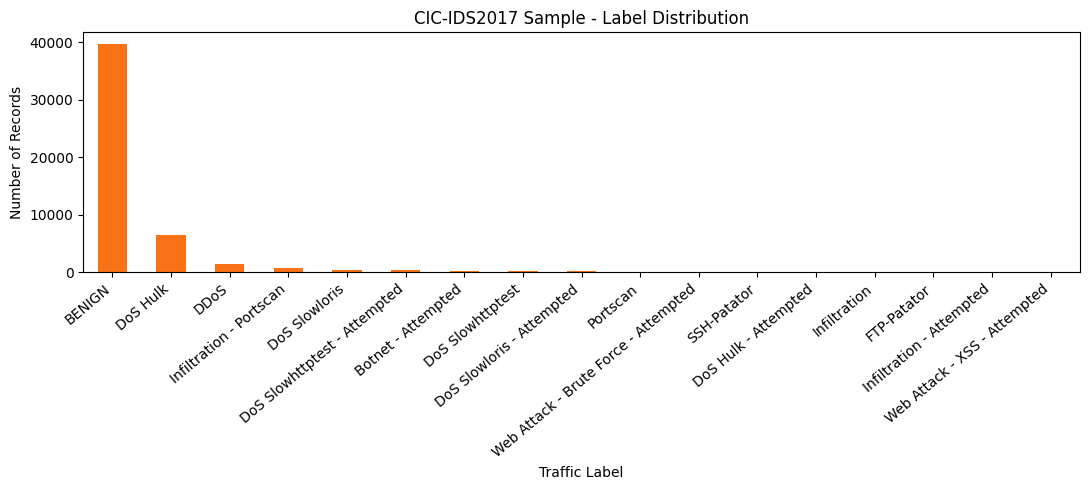


CAPTURE DAY VS TRAFFIC LABEL


Label,BENIGN,Botnet - Attempted,DDoS,DoS Hulk,DoS Hulk - Attempted,DoS Slowhttptest,DoS Slowhttptest - Attempted,DoS Slowloris,DoS Slowloris - Attempted,FTP-Patator,Infiltration,Infiltration - Attempted,Infiltration - Portscan,Portscan,SSH-Patator,Web Attack - Brute Force - Attempted,Web Attack - XSS - Attempted
Capture_Day,,,,,,,,,,,,,,,,,
Friday,8252,241,1458,0,0,0,0,0,0,0,0,0,0,49,0,0,0
Monday,10000,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Thursday,9172,0,0,0,0,0,0,0,0,0,2,1,815,0,0,9,1
Tuesday,9997,0,0,0,0,0,0,0,0,1,0,0,0,0,2,0,0
Wednesday,2347,0,0,6568,2,186,345,377,175,0,0,0,0,0,0,0,0


In [49]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Basic dataset information
total_rows = len(df)
total_columns = len(df.columns)

# 2. Missing values
missing_values = df.isnull().sum()
missing_report = missing_values[missing_values > 0].sort_values(
    ascending=False
)

# 3. Duplicate records
duplicate_count = int(df.duplicated().sum())

# 4. Infinite values in numerical columns
numeric_df = df.select_dtypes(include=np.number)
infinite_count = int(
    np.isinf(numeric_df.to_numpy()).sum()
)

# 5. Constant columns
constant_columns = [
    col for col in df.columns
    if df[col].nunique(dropna=False) <= 1
]

# 6. Label distribution
label_counts = df["Label"].value_counts(dropna=False)

label_percentages = (
    df["Label"].value_counts(normalize=True, dropna=False) * 100
).round(2)

label_report = pd.DataFrame({
    "Record Count": label_counts,
    "Percentage (%)": label_percentages
})

# 7. Capture day distribution
day_report = (
    df["Capture_Day"]
    .value_counts(dropna=False)
    .rename_axis("Capture Day")
    .reset_index(name="Record Count")
)

# 8. Normal vs non-benign-labelled records
normal_count = int(
    (df["Label"].astype(str).str.upper() == "BENIGN").sum()
)

non_benign_count = total_rows - normal_count

# 9. Print audit summary
print("=" * 50)
print("CYBERSCOPE AI - DATASET QUALITY AUDIT")
print("=" * 50)

print(f"\nTotal records: {total_rows:,}")
print(f"Total columns: {total_columns}")
print(f"Duplicate records: {duplicate_count:,}")
print(f"Infinite numerical values: {infinite_count:,}")
print(f"Missing-value columns: {len(missing_report)}")
print(f"Constant columns: {len(constant_columns)}")

print("\nNORMAL VS NON-BENIGN-LABELLED TRAFFIC")
print(f"Benign records: {normal_count:,}")
print(f"Other labelled records: {non_benign_count:,}")

print("\nMISSING VALUE REPORT")
if missing_report.empty:
    print("No missing values found.")
else:
    print(missing_report)

print("\nCONSTANT COLUMNS")
print(constant_columns if constant_columns else "None found.")

print("\nLABEL DISTRIBUTION")
display(label_report)

print("\nCAPTURE DAY DISTRIBUTION")
display(day_report)

# 10. Visualize label distribution
plt.figure(figsize=(11, 5))
label_counts.plot(kind="bar", color="#F97316")
plt.title("CIC-IDS2017 Sample - Label Distribution")
plt.xlabel("Traffic Label")
plt.ylabel("Number of Records")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.show()

# 11. Capture day vs traffic label
day_label_table = pd.crosstab(
    df["Capture_Day"],
    df["Label"]
)

print("\nCAPTURE DAY VS TRAFFIC LABEL")
display(day_label_table)

In [50]:
# STEP 23: CREATE A CLEAN ANALYSIS DATASET

# Keep the original dataset unchanged
df_analysis = df.copy()

# Remove columns that have only one unique value
constant_columns = [
    col for col in df_analysis.columns
    if df_analysis[col].nunique(dropna=False) <= 1
]

df_analysis = df_analysis.drop(columns=constant_columns)

# Remove duplicate rows if any exist
df_analysis = df_analysis.drop_duplicates()

# Replace infinite numerical values with NaN
numeric_columns = df_analysis.select_dtypes(
    include=np.number
).columns

df_analysis[numeric_columns] = (
    df_analysis[numeric_columns]
    .replace([np.inf, -np.inf], np.nan)
)

# Display the results
print("=" * 50)
print("CYBERSCOPE AI - CLEAN DATASET")
print("=" * 50)

print("Original shape:", df.shape)
print("Cleaned shape:", df_analysis.shape)

print("\nRemoved constant columns:")
print(constant_columns)

print("\nRemaining missing values:",
      df_analysis.isnull().sum().sum())

print("\nRemaining duplicate records:",
      df_analysis.duplicated().sum())

print("\nCleaned dataset preview:")
display(df_analysis.head())

CYBERSCOPE AI - CLEAN DATASET
Original shape: (50000, 94)
Cleaned shape: (50000, 91)

Removed constant columns:
['Fwd URG Flags', 'Bwd URG Flags', 'URG Flag Count']

Remaining missing values: 0

Remaining duplicate records: 0

Cleaned dataset preview:


,Src IP dec,Src Port,Dst IP dec,Dst Port,Protocol,Timestamp,Flow Duration,Total Fwd Packet,Total Bwd packets,Total Length of Fwd Packet,...,ICMP Code,ICMP Type,Total TCP Flow Time,Label,Attempted Category,Capture_Day,Source_IP,Destination_IP,Protocol_Name,Traffic_Status
0,3232238085,51800,1745882639,443,6,44:54.8,90053802,3,3,3,...,-1,-1,226336373,BENIGN,-1,Monday,192.168.10.5,104.16.14.15,TCP,Normal
1,3232238094,62670,3232238083,53,17,54:58.5,153412,4,4,132,...,-1,-1,0,BENIGN,-1,Monday,192.168.10.14,192.168.10.3,UDP,Normal
2,3232238083,62343,3232238081,53,17,35:01.8,30940,1,1,52,...,-1,-1,0,BENIGN,-1,Monday,192.168.10.3,192.168.10.1,UDP,Normal
3,3232238083,60759,3232238081,53,17,28:56.0,53703,1,1,58,...,-1,-1,0,BENIGN,-1,Monday,192.168.10.3,192.168.10.1,UDP,Normal
4,3232238083,60091,3232238081,53,17,33:10.6,79704,1,1,45,...,-1,-1,0,BENIGN,-1,Monday,192.168.10.3,192.168.10.1,UDP,Normal


In [51]:
import json

def calculate_dataset_insights():

    data = df_analysis.copy()

    # Separate normal and non-benign-labelled traffic
    malicious = data[
        data["Label"].astype(str).str.upper() != "BENIGN"
    ]

    # 1. Attack distribution
    attack_distribution = (
        malicious["Label"].value_counts().to_dict()
    )

    # 2. Capture day analysis
    daily_total = data.groupby("Capture_Day").size()

    daily_non_benign = (
        malicious.groupby("Capture_Day").size()
    )

    daily_report = {}

    for day in daily_total.index:
        total = int(daily_total[day])
        other = int(daily_non_benign.get(day, 0))

        daily_report[str(day)] = {
            "total_records": total,
            "non_benign_labelled_records": other,
            "non_benign_percentage": round(
                (other / total) * 100, 2
            ) if total else 0
        }

    # 3. Frequently appearing destination ports
    top_ports = (
        malicious["Dst Port"]
        .value_counts()
        .head(10)
        .to_dict()
    )

    # 4. Frequently appearing source IPs
    top_source_ips = (
        malicious["Source_IP"]
        .value_counts()
        .head(10)
        .to_dict()
    )

    # 5. Protocol distribution
    protocol_distribution = (
        data["Protocol_Name"]
        .value_counts()
        .to_dict()
    )

    return {
        "total_records": len(data),
        "total_non_benign_labelled_records": len(malicious),
        "attack_distribution": attack_distribution,
        "daily_report": daily_report,
        "top_destination_ports": top_ports,
        "top_source_ips": top_source_ips,
        "protocol_distribution": protocol_distribution
    }


# Generate the report
insights = calculate_dataset_insights()

print("CYBERSCOPE AI - AUTOMATIC DATASET INSIGHTS")
print("=" * 55)

print(json.dumps(insights, indent=4, default=str))

CYBERSCOPE AI - AUTOMATIC DATASET INSIGHTS
{
    "total_records": 50000,
    "total_non_benign_labelled_records": 10232,
    "attack_distribution": {
        "DoS Hulk": 6568,
        "DDoS": 1458,
        "Infiltration - Portscan": 815,
        "DoS Slowloris": 377,
        "DoS Slowhttptest - Attempted": 345,
        "Botnet - Attempted": 241,
        "DoS Slowhttptest": 186,
        "DoS Slowloris - Attempted": 175,
        "Portscan": 49,
        "Web Attack - Brute Force - Attempted": 9,
        "SSH-Patator": 2,
        "DoS Hulk - Attempted": 2,
        "Infiltration": 2,
        "FTP-Patator": 1,
        "Infiltration - Attempted": 1,
        "Web Attack - XSS - Attempted": 1
    },
    "daily_report": {
        "Friday": {
            "total_records": 10000,
            "non_benign_labelled_records": 1748,
            "non_benign_percentage": 17.48
        },
        "Monday": {
            "total_records": 10000,
            "non_benign_labelled_records": 0,
            "non_

In [52]:
def generate_intelligence_report():

    insights = calculate_dataset_insights()

    prompt = f"""
You are CyberScope AI, a cybersecurity dataset analyst.

Analyze the following actual statistics from the
CIC-IDS2017 dataset sample.

DATA:
{json.dumps(insights, indent=2, default=str)}

Prepare a report with these sections:

1. Dataset Summary
2. Important Traffic Patterns
3. Attack Activity Across Capture Days
4. Destination Port Observations
5. Source IP Observations
6. Network Protocol Observations
7. Further Investigation Recommendations

RULES:
- Use only the statistics provided.
- Do not invent numbers or attack events.
- Explain findings in beginner-friendly language.
- Do not call an IP a confirmed attacker.
- Do not claim that a destination port was attacked
  merely because it appears frequently.
- Explain that non-BENIGN labels are dataset labels.
- Mention that this is a loaded sample, not necessarily
  the full original dataset.
- Distinguish observations from assumptions.
- Do not claim to detect live attacks.

"""

    response = client.chat.completions.create(
        model=MODEL,
        messages=[
            {
                "role": "user",
                "content": prompt
            }
        ],
        temperature=0.2
    )

    return response.choices[0].message.content


# Generate and display the AI report
intelligence_report = generate_intelligence_report()

print(intelligence_report)

**CyberScope AI – CIC‑IDS2017 Sample Analysis Report**  
*Prepared for: Network Security Team*  
*Date: 30 Oct 2026*  

---

## 1. Dataset Summary  

| Item | Value | Comment |
|------|-------|---------|
| Total records in the sample | **50 000** | The sample is a subset of the full CIC‑IDS2017 dataset. |
| Records labeled “non‑BENIGN” | **10 232** | These are the entries that the dataset’s labeling process marked as potential attacks or suspicious activity. |
| Percentage of non‑BENIGN records | **≈ 20.5 %** | (10 232 ÷ 50 000 × 100) |
| Protocol distribution | UDP: 34 554, TCP: 15 310, Other: 105, ICMP: 31 | UDP dominates the traffic in this sample. |
| Top source IP | 172.16.0.1 (9 175 hits) | The most frequent source in the sample. |
| Top destination port | 80 (9 138 hits) | HTTP traffic is the most common. |

> **Key takeaway:** About one‑fifth of the traffic in this sample is flagged as potentially malicious. The majority of packets are UDP, and HTTP (port 80) traffic dominates 

In [53]:
from datasets import load_dataset
import pandas as pd

daily_urls = {
    "Monday": "https://huggingface.co/datasets/bvk/CICIDS-2017/resolve/main/monday.csv",
    "Tuesday": "https://huggingface.co/datasets/bvk/CICIDS-2017/resolve/main/tuesday.csv",
    "Wednesday": "https://huggingface.co/datasets/bvk/CICIDS-2017/resolve/main/wednesday.csv",
    "Thursday": "https://huggingface.co/datasets/bvk/CICIDS-2017/resolve/main/thursday.csv",
    "Friday": "https://huggingface.co/datasets/bvk/CICIDS-2017/resolve/main/friday.csv"
}

sampled_days = []

for day, url in daily_urls.items():

    print(f"Loading and shuffling {day}...")

    dataset = load_dataset(
        "csv",
        data_files=url,
        split="train",
        streaming=True
    )

    shuffled = dataset.shuffle(
        seed=42,
        buffer_size=100000
    )

    sampled = list(shuffled.take(10000))

    day_df = pd.DataFrame(sampled)
    day_df["Capture_Day"] = day

    sampled_days.append(day_df)

    print(f"{day}: {len(day_df):,} records collected")

# Combine all five samples
df = pd.concat(sampled_days, ignore_index=True)

print("\nNew sample shape:", df.shape)
print("\nNew label distribution:")
display(df["Label"].value_counts())

print("\nCapture day distribution:")
display(df["Capture_Day"].value_counts())

Loading and shuffling Monday...
Monday: 10,000 records collected
Loading and shuffling Tuesday...
Tuesday: 10,000 records collected
Loading and shuffling Wednesday...
Wednesday: 10,000 records collected
Loading and shuffling Thursday...
Thursday: 10,000 records collected
Loading and shuffling Friday...
Friday: 10,000 records collected

New sample shape: (50000, 90)

New label distribution:


,count
Label,
BENIGN,39768
DoS Hulk,6568
DDoS,1458
Infiltration - Portscan,815
DoS Slowloris,377
DoS Slowhttptest - Attempted,345
Botnet - Attempted,241
DoS Slowhttptest,186
DoS Slowloris - Attempted,175



Capture day distribution:


,count
Capture_Day,
Monday,10000
Tuesday,10000
Wednesday,10000
Thursday,10000
Friday,10000


In [56]:
# Compare old and new samples

# Only select columns that exist in both DataFrames
common_cols = [col for col in df.columns if col in df_analysis.columns]

old_raw = df_analysis[common_cols].copy()
new_raw = df[common_cols].copy()

print("OLD SAMPLE SHAPE (matching columns):", old_raw.shape)
print("NEW SAMPLE SHAPE (matching columns):", new_raw.shape)

# Compare label counts
print("\nLABEL COUNTS IDENTICAL?")
print(
    old_raw["Label"].value_counts().sort_index().equals(
        new_raw["Label"].value_counts().sort_index()
    )
)

# Compare actual records using row hashes
old_hashes = pd.util.hash_pandas_object(
    old_raw.astype(str), index=False
)

new_hashes = pd.util.hash_pandas_object(
    new_raw.astype(str), index=False
)

old_set = set(old_hashes)
new_set = set(new_hashes)

common_records = len(old_set.intersection(new_set))

print("\nUNIQUE OLD RECORDS:", len(old_set))
print("UNIQUE NEW RECORDS:", len(new_set))
print("COMMON RECORDS:", common_records)

print(
    "Percentage of old unique records also in new sample:",
    round(common_records / max(len(old_set), 1) * 100, 2),
    "%"
)

# Compare daily label distributions
print("\nDAILY LABEL COMPARISON:")
display(pd.crosstab(new_raw["Capture_Day"], new_raw["Label"]))

OLD SAMPLE SHAPE (matching columns): (50000, 87)
NEW SAMPLE SHAPE (matching columns): (50000, 87)

LABEL COUNTS IDENTICAL?
True

UNIQUE OLD RECORDS: 50000
UNIQUE NEW RECORDS: 50000
COMMON RECORDS: 50000
Percentage of old unique records also in new sample: 100.0 %

DAILY LABEL COMPARISON:


Label,BENIGN,Botnet - Attempted,DDoS,DoS Hulk,DoS Hulk - Attempted,DoS Slowhttptest,DoS Slowhttptest - Attempted,DoS Slowloris,DoS Slowloris - Attempted,FTP-Patator,Infiltration,Infiltration - Attempted,Infiltration - Portscan,Portscan,SSH-Patator,Web Attack - Brute Force - Attempted,Web Attack - XSS - Attempted
Capture_Day,,,,,,,,,,,,,,,,,
Friday,8252,241,1458,0,0,0,0,0,0,0,0,0,0,49,0,0,0
Monday,10000,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Thursday,9172,0,0,0,0,0,0,0,0,0,2,1,815,0,0,9,1
Tuesday,9997,0,0,0,0,0,0,0,0,1,0,0,0,0,2,0,0
Wednesday,2347,0,0,6568,2,186,345,377,175,0,0,0,0,0,0,0,0


In [57]:
# Check whether the records are in exactly the same order

print("Are row sequences identical?")
print(old_hashes.reset_index(drop=True).equals(
    new_hashes.reset_index(drop=True)
))

# Compare first 10 row hashes
print("\nFirst 10 old hashes:")
print(old_hashes.head(10).tolist())

print("\nFirst 10 new hashes:")
print(new_hashes.head(10).tolist())

# Check how many rows differ by position
different_positions = int(
    (old_hashes.reset_index(drop=True) !=
     new_hashes.reset_index(drop=True)).sum()
)

print("\nRows in different positions:", different_positions)

Are row sequences identical?
True

First 10 old hashes:
[112301647501056197, 15566417087101287109, 10300493338609463444, 6039748424028735849, 7403581127126226950, 8129445092504127980, 7163921882960996645, 4976214007009186329, 8570074219581119651, 3405388786121420687]

First 10 new hashes:
[112301647501056197, 15566417087101287109, 10300493338609463444, 6039748424028735849, 7403581127126226950, 8129445092504127980, 7163921882960996645, 4976214007009186329, 8570074219581119651, 3405388786121420687]

Rows in different positions: 0


In [58]:
import random
import pandas as pd
from datasets import load_dataset

# Preserve the current sample
df_previous = df.copy(deep=True)

daily_urls = {
    "Monday": "https://huggingface.co/datasets/bvk/CICIDS-2017/resolve/main/monday.csv",
    "Tuesday": "https://huggingface.co/datasets/bvk/CICIDS-2017/resolve/main/tuesday.csv",
    "Wednesday": "https://huggingface.co/datasets/bvk/CICIDS-2017/resolve/main/wednesday.csv",
    "Thursday": "https://huggingface.co/datasets/bvk/CICIDS-2017/resolve/main/thursday.csv",
    "Friday": "https://huggingface.co/datasets/bvk/CICIDS-2017/resolve/main/friday.csv"
}

sample_size = 10000
sampled_days = []
scanned_counts = {}

for day_number, (day, url) in enumerate(daily_urls.items()):

    print(f"\nScanning the complete {day} file...")

    dataset = load_dataset(
        "csv",
        data_files=url,
        split="train",
        streaming=True
    )

    rng = random.Random(42 + day_number)
    reservoir = []
    total_scanned = 0

    # Reservoir sampling
    for record in dataset:
        total_scanned += 1

        if total_scanned <= sample_size:
            reservoir.append(record)
        else:
            position = rng.randrange(total_scanned)

            if position < sample_size:
                reservoir[position] = record

        if total_scanned % 500000 == 0:
            print(f"Scanned {total_scanned:,} records...")

    day_df = pd.DataFrame(reservoir)
    day_df["Capture_Day"] = day

    sampled_days.append(day_df)
    scanned_counts[day] = total_scanned

    print(f"{day}: scanned {total_scanned:,} records")
    print(f"{day}: selected {len(day_df):,} records")

# Combine the samples
df = pd.concat(sampled_days, ignore_index=True)

print("\nRESERVOIR SAMPLING COMPLETE")
print("New dataset shape:", df.shape)

print("\nRecords scanned per day:")
print(scanned_counts)

print("\nNew label distribution:")
display(df["Label"].value_counts())

print("\nCapture day distribution:")
display(df["Capture_Day"].value_counts())


Scanning the complete Monday file...
Monday: scanned 371,621 records
Monday: selected 10,000 records

Scanning the complete Tuesday file...
Tuesday: scanned 322,078 records
Tuesday: selected 10,000 records

Scanning the complete Wednesday file...
Wednesday: scanned 496,640 records
Wednesday: selected 10,000 records

Scanning the complete Thursday file...
Thursday: scanned 362,075 records
Thursday: selected 10,000 records

Scanning the complete Friday file...
Scanned 500,000 records...
Friday: scanned 547,557 records
Friday: selected 10,000 records

RESERVOIR SAMPLING COMPLETE
New dataset shape: (50000, 90)

Records scanned per day:
{'Monday': 371621, 'Tuesday': 322078, 'Wednesday': 496640, 'Thursday': 362075, 'Friday': 547557}

New label distribution:


,count
Label,
BENIGN,39451
DoS Hulk,3272
Portscan,2834
Infiltration - Portscan,2004
DDoS,1734
DoS GoldenEye,131
FTP-Patator,130
SSH-Patator,94
DoS Slowhttptest - Attempted,68



Capture day distribution:


,count
Capture_Day,
Monday,10000
Tuesday,10000
Wednesday,10000
Thursday,10000
Friday,10000


In [59]:
import pandas as pd
import numpy as np
import ipaddress

# 1. Start with the new reservoir sample
df_analysis = df.copy()

# 2. Convert decimal IP addresses into readable IPv4 addresses
def convert_ip(value):
    try:
        if pd.isna(value):
            return None
        return str(ipaddress.IPv4Address(int(value)))
    except (ValueError, TypeError, OverflowError):
        return str(value)

df_analysis["Source_IP"] = (
    df_analysis["Src IP dec"].apply(convert_ip)
)

df_analysis["Destination_IP"] = (
    df_analysis["Dst IP dec"].apply(convert_ip)
)

# 3. Convert protocol numbers into readable names
protocol_mapping = {
    1: "ICMP",
    6: "TCP",
    17: "UDP"
}

df_analysis["Protocol_Name"] = (
    df_analysis["Protocol"]
    .map(protocol_mapping)
    .fillna("Other")
)

# 4. Classify using the dataset's existing labels
# These are dataset labels, not independent attack verification.
df_analysis["Traffic_Status"] = np.where(
    df_analysis["Label"].astype(str).str.upper() == "BENIGN",
    "Normal",
    "Malicious"
)

# 5. Identify constant columns
constant_columns = [
    col for col in df_analysis.columns
    if df_analysis[col].nunique(dropna=False) <= 1
]

# 6. Remove constant columns from analysis copy
df_analysis = df_analysis.drop(columns=constant_columns)

# 7. Replace infinite numerical values
numeric_columns = df_analysis.select_dtypes(
    include=np.number
).columns

df_analysis[numeric_columns] = (
    df_analysis[numeric_columns]
    .replace([np.inf, -np.inf], np.nan)
)

# 8. Quality report
print("=" * 55)
print("CYBERSCOPE AI - UPDATED ANALYSIS DATASET")
print("=" * 55)

print("Raw dataset shape:", df.shape)
print("Analysis dataset shape:", df_analysis.shape)

print("\nRemoved constant columns:")
print(constant_columns if constant_columns else "None")

print("\nMissing values:", df_analysis.isnull().sum().sum())
print("Duplicate records:", df_analysis.duplicated().sum())

print("\nUpdated label distribution:")
display(df_analysis["Label"].value_counts())

print("\nUpdated traffic status:")
display(df_analysis["Traffic_Status"].value_counts())

print("\nUpdated dataset preview:")
display(df_analysis.head())

CYBERSCOPE AI - UPDATED ANALYSIS DATASET
Raw dataset shape: (50000, 90)
Analysis dataset shape: (50000, 93)

Removed constant columns:
['Bwd URG Flags']

Missing values: 0
Duplicate records: 2

Updated label distribution:


,count
Label,
BENIGN,39451
DoS Hulk,3272
Portscan,2834
Infiltration - Portscan,2004
DDoS,1734
DoS GoldenEye,131
FTP-Patator,130
SSH-Patator,94
DoS Slowhttptest - Attempted,68



Updated traffic status:


,count
Traffic_Status,
Normal,39451
Malicious,10549



Updated dataset preview:


,Src IP dec,Src Port,Dst IP dec,Dst Port,Protocol,Timestamp,Flow Duration,Total Fwd Packet,Total Bwd packets,Total Length of Fwd Packet,...,ICMP Code,ICMP Type,Total TCP Flow Time,Label,Attempted Category,Capture_Day,Source_IP,Destination_IP,Protocol_Name,Traffic_Status
0,3232238097,123,759979125,123,17,46:08.8,111880,1,1,48,...,-1,-1,0,BENIGN,-1,Monday,192.168.10.17,45.76.92.117,UDP,Normal
1,3232238088,53433,1746149122,443,6,38:57.2,5808836,9,7,321,...,-1,-1,5808836,BENIGN,-1,Monday,192.168.10.8,104.20.31.2,TCP,Normal
2,3232238089,49371,3232238083,53,17,14:36.0,164,2,2,96,...,-1,-1,0,BENIGN,-1,Monday,192.168.10.9,192.168.10.3,UDP,Normal
3,3232238085,54651,2899905070,443,6,28:55.7,134783,8,9,441,...,-1,-1,134783,BENIGN,-1,Monday,192.168.10.5,172.217.10.46,TCP,Normal
4,3232238092,123,760155097,123,17,57:30.6,68045057,8,8,384,...,-1,-1,0,BENIGN,-1,Monday,192.168.10.12,45.79.11.217,UDP,Normal


In [60]:
# Preserve the original 50,000-row reservoir sample
df_raw = df.copy(deep=True)

# Inspect duplicate rows before removal
duplicate_rows = df_analysis[
    df_analysis.duplicated(keep=False)
]

print("Rows involved in duplicate records:")
display(duplicate_rows)

# Remove exact duplicate records
df_analysis = df_analysis.drop_duplicates().copy()

# Make the cleaned analysis dataset available
# to the existing dashboard functions
df = df_analysis.copy(deep=True)

print("\n" + "=" * 50)
print("CYBERSCOPE AI - FINAL DATASET CHECK")
print("=" * 50)

print("Raw sample shape:", df_raw.shape)
print("Clean analysis shape:", df_analysis.shape)
print("Remaining duplicates:", df_analysis.duplicated().sum())
print("Remaining missing values:", df_analysis.isnull().sum().sum())

print("\nTraffic distribution:")
display(df_analysis["Label"].value_counts())

print("\nDaily distribution:")
display(df_analysis["Capture_Day"].value_counts())

Rows involved in duplicate records:


,Src IP dec,Src Port,Dst IP dec,Dst Port,Protocol,Timestamp,Flow Duration,Total Fwd Packet,Total Bwd packets,Total Length of Fwd Packet,...,ICMP Code,ICMP Type,Total TCP Flow Time,Label,Attempted Category,Capture_Day,Source_IP,Destination_IP,Protocol_Name,Traffic_Status
30365,3232238088,63036,3232238131,3920,6,14:37.5,21,1,1,0,...,-1,-1,21,Infiltration - Portscan,-1,Thursday,192.168.10.8,192.168.10.51,TCP,Malicious
33331,3232238088,63036,3232238131,3920,6,14:37.5,21,1,1,0,...,-1,-1,21,Infiltration - Portscan,-1,Thursday,192.168.10.8,192.168.10.51,TCP,Malicious
33574,3232238088,34036,3232238096,4006,6,29:27.9,24,1,1,0,...,-1,-1,24,Infiltration - Portscan,-1,Thursday,192.168.10.8,192.168.10.16,TCP,Malicious
35608,3232238088,34036,3232238096,4006,6,29:27.9,24,1,1,0,...,-1,-1,24,Infiltration - Portscan,-1,Thursday,192.168.10.8,192.168.10.16,TCP,Malicious



CYBERSCOPE AI - FINAL DATASET CHECK
Raw sample shape: (50000, 90)
Clean analysis shape: (49998, 93)
Remaining duplicates: 0
Remaining missing values: 0

Traffic distribution:


,count
Label,
BENIGN,39451
DoS Hulk,3272
Portscan,2834
Infiltration - Portscan,2002
DDoS,1734
DoS GoldenEye,131
FTP-Patator,130
SSH-Patator,94
DoS Slowhttptest - Attempted,68



Daily distribution:


,count
Capture_Day,
Monday,10000
Tuesday,10000
Wednesday,10000
Friday,10000
Thursday,9998


In [61]:
import json

def calculate_dataset_insights():

    data = df_analysis.copy()

    non_benign = data[
        data["Label"].astype(str).str.upper() != "BENIGN"
    ]

    # 1. Attack label distribution
    attack_distribution = (
        non_benign["Label"].value_counts().to_dict()
    )

    # 2. Daily traffic patterns
    daily_report = {}

    for day, group in data.groupby("Capture_Day"):

        total = len(group)

        other = int(
            (group["Label"].astype(str).str.upper() != "BENIGN").sum()
        )

        daily_report[str(day)] = {
            "total_flows": total,
            "non_benign_labelled_flows": other,
            "percentage": round(other / total * 100, 2)
        }

    # 3. Frequently appearing destination ports
    top_ports = (
        non_benign["Dst Port"]
        .value_counts()
        .head(10)
        .to_dict()
    )

    # 4. Frequently appearing source IPs
    top_ips = (
        non_benign["Source_IP"]
        .value_counts()
        .head(10)
        .to_dict()
    )

    # 5. Protocol distribution
    protocols = data["Protocol_Name"].value_counts().to_dict()

    return {
        "total_records": len(data),
        "benign_records": int(
            (data["Label"].astype(str).str.upper() == "BENIGN").sum()
        ),
        "non_benign_labelled_records": len(non_benign),
        "unique_labels": int(data["Label"].nunique()),
        "attack_distribution": attack_distribution,
        "daily_traffic": daily_report,
        "top_destination_ports": top_ports,
        "frequent_source_ips": top_ips,
        "protocol_distribution": protocols
    }


def generate_intelligence_report():

    insights = calculate_dataset_insights()

    prompt = f"""
You are CyberScope AI, a cybersecurity data analyst.

Analyze the following statistics from a 49,998-record
sample of the CIC-IDS2017 dataset.

DATA:
{json.dumps(insights, indent=2, default=str)}

Create a professional report with these sections:

1. Executive Summary
2. Dataset Statistics
3. Traffic and Attack Label Distribution
4. Daily Traffic Analysis
5. Destination Port Observations
6. Source IP Observations
7. Protocol Analysis
8. Potential Areas for Further Investigation
9. Limitations of This Analysis

IMPORTANT RULES:

- Use only the supplied statistics.
- Do not invent values or findings.
- Explain technical terms simply.
- Do not identify an IP as a confirmed attacker.
- Frequent ports do not automatically indicate attacks.
- Treat non-BENIGN values as dataset labels.
- Distinguish observations from assumptions.
- This is a day-balanced sample, not the entire dataset.
- Do not claim to detect live attacks.
- Mention that exact duplicate records were removed.
"""

    response = client.chat.completions.create(
        model=MODEL,
        messages=[
            {"role": "user", "content": prompt}
        ],
        temperature=0.2
    )

    return response.choices[0].message.content


# Generate the report
insights = calculate_dataset_insights()

print("DATASET INSIGHTS CALCULATED SUCCESSFULLY")
print("=" * 50)

print(json.dumps(insights, indent=2, default=str))

print("\n\nCYBERSCOPE AI - INTELLIGENCE REPORT")
print("=" * 50)

intelligence_report = generate_intelligence_report()

print(intelligence_report)

DATASET INSIGHTS CALCULATED SUCCESSFULLY
{
  "total_records": 49998,
  "benign_records": 39451,
  "non_benign_labelled_records": 10547,
  "unique_labels": 23,
  "attack_distribution": {
    "DoS Hulk": 3272,
    "Portscan": 2834,
    "Infiltration - Portscan": 2002,
    "DDoS": 1734,
    "DoS GoldenEye": 131,
    "FTP-Patator": 130,
    "SSH-Patator": 94,
    "DoS Slowhttptest - Attempted": 68,
    "Botnet - Attempted": 65,
    "DoS Slowloris": 59,
    "DoS Slowloris - Attempted": 41,
    "DoS Slowhttptest": 31,
    "Web Attack - Brute Force - Attempted": 29,
    "Botnet": 22,
    "Web Attack - XSS - Attempted": 17,
    "DoS Hulk - Attempted": 11,
    "SSH-Patator - Attempted": 2,
    "FTP-Patator - Attempted": 1,
    "DoS GoldenEye - Attempted": 1,
    "Heartbleed": 1,
    "Web Attack - Brute Force": 1,
    "Infiltration": 1
  },
  "daily_traffic": {
    "Friday": {
      "total_flows": 10000,
      "non_benign_labelled_flows": 4655,
      "percentage": 46.55
    },
    "Monday": {
  

In [62]:
def generate_intelligence_report():

    insights = calculate_dataset_insights()

    prompt = f"""
You are a cybersecurity data analyst.

Generate a concise, professional intelligence report
for CyberScope AI using ONLY the statistics below.

DATA:
{json.dumps(insights, indent=2, default=str)}

Use these sections:

1. Executive Summary
2. Dataset Statistics
3. Attack Label Distribution
4. Daily Sample Analysis
5. Destination Port Analysis
6. Source IP Observations
7. Protocol Distribution
8. Security Recommendations
9. Limitations

IMPORTANT RULES:

- There are 49,998 records in the cleaned sample.
- There are 23 total labels, including BENIGN.
- There are 22 non-BENIGN labels.
- Do not invent statistics or observations.
- Clearly distinguish BENIGN from non-BENIGN-labelled records.
- This is a day-balanced sample of approximately 10,000
  records per day, not the complete original dataset.
- Daily percentages describe only the selected sample.
- Do not claim Monday had no attacks in the original dataset.
- Do not claim that the sample represents real-world
  attack prevalence.
- Frequent source IPs are investigation leads, not
  confirmed attackers.
- Frequent destination ports are observations, not
  proof of malicious activity.
- Do not assume that every non-BENIGN label represents
  a confirmed real-world incident.
- Mention that duplicate records were removed.
- Keep the report concise, complete and professional.
- Do not stop halfway through a table.
- If the report is too long, summarize the smaller
  attack categories instead of omitting sections.

End with a short conclusion explaining what CyberScope AI
can and cannot determine from this dataset.
"""

    response = client.chat.completions.create(
        model=MODEL,
        messages=[
            {
                "role": "user",
                "content": prompt
            }
        ],
        temperature=0.1
    )

    return response.choices[0].message.content

In [69]:
def export_intelligence_report():

    report = generate_intelligence_report()

    file_path = "/content/CyberScope_AI_Intelligence_Report.md"

    with open(file_path, "w", encoding="utf-8") as file:
        file.write(report)

    return file_path

In [ ]:
intelligence_report = generate_intelligence_report()

print("=" * 60)
print("CYBERSCOPE AI - INTELLIGENCE REPORT")
print("=" * 60)
print(intelligence_report)

with gr.Blocks(
    title="CyberScope AI"
) as cyberscope_app:

    gr.Markdown("# 🛡️ CyberScope AI", elem_classes="main-heading")
    gr.Markdown(
        "Your AI-powered cybersecurity dataset understanding platform.",
        elem_classes="sub-heading"
    )

    with gr.Tabs():

        # TAB 1: OVERVIEW
        with gr.Tab("📊 Overview"):
            gr.Markdown("## Dataset Summary")

            overview_output = gr.Markdown(
                value=get_overview_text()
            )

            overview_plot = gr.Plot(
                value=create_overview_chart()
            )

            refresh_overview = gr.Button(
                "Refresh Overview",
                variant="primary"
            )

            refresh_overview.click(
                fn=lambda: (
                    get_overview_text(),
                    create_overview_chart()
                ),
                outputs=[overview_output, overview_plot]
            )

        # TAB 2: DATASET EXPLORER
        with gr.Tab("🔎 Dataset Explorer"):
            gr.Markdown("## Explore Network Traffic")

            with gr.Row():
                day_filter = gr.Dropdown(
                    choices=days,
                    value="All Days",
                    label="Capture Day"
                )

                attack_filter = gr.Dropdown(
                    choices=attacks,
                    value="All Attacks",
                    label="Traffic Label"
                )

                row_limit = gr.Slider(
                    minimum=10,
                    maximum=500,
                    value=100,
                    step=10,
                    label="Preview Rows"
                )

            explore_button = gr.Button(
                "Explore Dataset",
                variant="primary"
            )

            explorer_summary = gr.Markdown()

            explorer_table = gr.Dataframe(
                label="Network Traffic Records",
                interactive=False
            )

            explorer_plot = gr.Plot()

            explore_button.click(
                fn=get_filtered_data,
                inputs=[day_filter, attack_filter, row_limit],
                outputs=[explorer_table, explorer_summary]
            )

            explore_button.click(
                fn=create_filtered_chart,
                inputs=[day_filter, attack_filter],
                outputs=explorer_plot
            )

            gr.Markdown("### Export Filtered Dataset")

            export_button = gr.Button("Export CSV")
            export_file = gr.File(label="Your CSV File")

            export_button.click(
                fn=export_filtered_data,
                inputs=[day_filter, attack_filter],
                outputs=export_file
            )

        # TAB 3: AI ASSISTANT
        with gr.Tab("🤖 AI Assistant"):
            gr.Markdown("## Ask CyberScope AI")

            gr.Markdown(
                "Ask questions about the CIC-IDS2017 network traffic dataset."
            )

            chatbot = gr.Chatbot(
                height=420,
                label="CyberScope AI Chat"
            )

            gr.Markdown("### Suggested Questions")

            with gr.Row():
                overview_btn = gr.Button("Dataset Overview")
                attack_btn = gr.Button("Attack Distribution")
                ip_btn = gr.Button("Suspicious Source IPs")

            with gr.Row():
                port_btn = gr.Button("Targeted Ports")
                protocol_btn = gr.Button("Network Protocols")
                daily_btn = gr.Button("Daily Traffic")

            overview_btn.click(
                fn=lambda history: suggested_response(
                    "Give me an overview of this dataset.", history
                ),
                inputs=chatbot,
                outputs=chatbot
            )

            attack_btn.click(
                fn=lambda history: suggested_response(
                    "Show me the attack distribution.", history
                ),
                inputs=chatbot,
                outputs=chatbot
            )

            ip_btn.click(
                fn=lambda history: suggested_response(
                    "Which source IPs appear most frequently in non-benign labelled traffic?",
                    history
                ),
                inputs=chatbot,
                outputs=chatbot
            )

            port_btn.click(
                fn=lambda history: suggested_response(
                    "Which destination ports appear most frequently in non-benign labelled traffic?",
                    history
                ),
                inputs=chatbot,
                outputs=chatbot
            )

            protocol_btn.click(
                fn=lambda history: suggested_response(
                    "Explain the network protocol distribution.", history
                ),
                inputs=chatbot,
                outputs=chatbot
            )

            daily_btn.click(
                fn=lambda history: suggested_response(
                    "Show me the traffic distribution across capture days.",
                    history
                ),
                inputs=chatbot,
                outputs=chatbot
            )

            with gr.Row():
                message_box = gr.Textbox(
                    placeholder="Ask something about your dataset...",
                    label="Your Question",
                    scale=8
                )

                send_button = gr.Button(
                    "Send",
                    variant="primary",
                    scale=1
                )

            send_button.click(
                fn=chat_response,
                inputs=[message_box, chatbot],
                outputs=[chatbot, message_box]
            )

            message_box.submit(
                fn=chat_response,
                inputs=[message_box, chatbot],
                outputs=[chatbot, message_box]
            )

        # TAB 4: AI INTELLIGENCE REPORT
        with gr.Tab("📑 Intelligence Report"):

            gr.Markdown("## 🛡️ AI-Generated Intelligence Report")

            gr.Markdown(
                """
                Generate a professional cybersecurity analysis
                based on the cleaned CIC-IDS2017 sample.

                The report includes dataset statistics, attack
                distribution, daily traffic, source IP observations,
                destination ports, security recommendations and
                dataset limitations.
                """
            )

            generate_report_btn = gr.Button(
                "Generate Intelligence Report",
                variant="primary"
            )

            report_output = gr.Markdown(
                value="Click the button above to generate your report."
            )

            generate_report_btn.click(
                fn=generate_intelligence_report,
                inputs=None,
                outputs=report_output
            )
            gr.Markdown("### Download Your Report")

    download_report_btn = gr.Button(
        "Generate & Download Report",
        variant="primary"
    )

    report_file = gr.File(
        label="Download Intelligence Report"
    )

    download_report_btn.click(
        fn=export_intelligence_report,
        inputs=None,
        outputs=report_file
    )

# -----------------------------------------
# LAUNCH THE APPLICATION
# -----------------------------------------

cyberscope_app.launch(
    theme=gr.themes.Base(
        primary_hue="orange",
        neutral_hue="slate"
    ),
    css=dashboard_css,
    share=True,
    debug=True
)

CYBERSCOPE AI - INTELLIGENCE REPORT
**CyberScope AI – Network Traffic Analysis Report**  
*Sample period: 5‑day balanced snapshot (Friday–Wednesday)*  

---

### 1. Executive Summary  
The 49,998‑record sample contains 39,451 benign flows and 10,547 labeled attack flows spanning 23 distinct labels (including BENIGN). The most frequent attacks are DoS Hulk, Portscan, and Infiltration – Portscan. Traffic is evenly split between TCP and UDP, with a small ICMP presence. Key observations:  
- **High‑volume HTTP traffic** (port 80) dominates the dataset.  
- **Frequent source IPs** (e.g., 172.16.0.1) account for a large share of flows.  
- **Daily variation** shows Friday and Wednesday with the highest non‑benign percentages (46.55 % and 36.15 % respectively).  

These insights can guide focused monitoring and resource allocation.

---

### 2. Dataset Statistics  
| Metric | Count |
|--------|-------|
| Total records | 49,998 |
| Benign records | 39,451 |
| Non‑benign‑labelled records | 10,5

In [64]:

print(intelligence_report[-1500:])

the selected sample and do not imply overall prevalence.*

---

### 5. Destination Port Analysis  
| Port | Count |
|------|-------|
| 80 | 5,403 |
| 21 | 136 |
| 22 | 102 |
| 8080 | 91 |
| 139 | 17 |
| 135 | 14 |
| 3000 | 13 |
| 3920 | 12 |
| 9535 | 11 |
| 5544 | 11 |

*Port 80 dominates traffic, consistent with web‑related activity. Other ports are observed but not confirmed as malicious.*

---

### 6. Source IP Observations  
| Source IP | Count |
|-----------|-------|
| 172.16.0.1 | 8,482 |
| 192.168.10.8 | 1,999 |
| 192.168.10.15 | 21 |
| 192.168.10.5 | 18 |
| 192.168.10.14 | 14 |
| 192.168.10.9 | 13 |

*These IPs are investigation leads; no definitive attribution to attackers is established.*

---

### 7. Protocol Distribution  
| Protocol | Count |
|----------|-------|
| TCP | 25,023 |
| UDP | 24,921 |
| ICMP | 19 |
| Other | 35 |

*TCP and UDP traffic dominate, as expected in typical network environments.*

---

### 8. Security Recommendations  

1. **Enhanced DoS Mitigation** 

In [65]:
def generate_intelligence_report():

    insights = calculate_dataset_insights()

    prompt = f"""
You are a cybersecurity data analyst.

Create a concise and complete report for CyberScope AI.

DATA:
{json.dumps(insights, indent=2, default=str)}

Include these 9 sections:

1. Executive Summary
2. Dataset Statistics
3. Attack Label Distribution
4. Daily Sample Analysis
5. Destination Port Analysis
6. Source IP Observations
7. Protocol Distribution
8. Security Recommendations
9. Limitations and Conclusion

RULES:

- Total records: 49,998.
- BENIGN records: 39,451.
- Non-BENIGN-labelled records: 10,547.
- Total labels: 23, including BENIGN.
- Non-BENIGN labels: 22.
- Include the supplied statistics accurately.
- This is a day-balanced sample, not the complete dataset.
- Daily percentages describe only this sample.
- Do not imply that Monday had no attacks in the original dataset.
- Do not claim the sample represents real-world attack prevalence.
- Frequent IPs are investigation leads, not confirmed attackers.
- Ports are observations, not proof of malicious activity.
- Avoid unsupported claims about typical network environments.
- Clearly distinguish dataset labels from verified incidents.
- Keep all sections concise.
- Section 9 MUST explain the limitations and what the tool
  cannot establish.
- End with a short conclusion.

Do not omit any section.
"""

    response = client.chat.completions.create(
        model=MODEL,
        messages=[
            {"role": "user", "content": prompt}
        ],
        temperature=0.1,
        max_completion_tokens=3000
    )

    return response.choices[0].message.content

In [66]:
intelligence_report = generate_intelligence_report()

print("=" * 60)
print("CYBERSCOPE AI - INTELLIGENCE REPORT")
print("=" * 60)

print(intelligence_report)

print("\n\nREPORT COMPLETION CHECK:")
print("Limitations section found:",
      "9." in intelligence_report and
      "Limitations" in intelligence_report)


CYBERSCOPE AI - INTELLIGENCE REPORT
**CyberScope AI – Network Traffic Analysis Report**  
*Sample period: 5 days (day‑balanced)*  

---

### 1. Executive Summary  
The 49,998‑record sample contains 39,451 benign flows and 10,547 flows with one of 22 non‑benign attack labels. The most frequent attacks are DoS Hulk, Portscan, and Infiltration – Portscan. Traffic is evenly split between TCP and UDP, with a small presence of ICMP and other protocols. The sample highlights several high‑volume source IPs and destination ports that warrant further investigation.

---

### 2. Dataset Statistics  
| Metric | Value |
|--------|-------|
| Total records | 49,998 |
| Benign records | 39,451 |
| Non‑benign‑labelled records | 10,547 |
| Total unique labels (including BENIGN) | 23 |
| Non‑benign labels | 22 |

---

### 3. Attack Label Distribution  
| Attack Type | Count |
|-------------|-------|
| DoS Hulk | 3,272 |
| Portscan | 2,834 |
| Infiltration – Portscan | 2,002 |
| DDoS | 1,734 |
| DoS Golde